<a href="https://colab.research.google.com/github/Mia-NK/Mia_INFO4670_Fall2026/blob/main/INFO_4670_Assignment_4_%5BLOGISTIC_REGRESSION%5D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 11: Assignment 4 - Logistic Regression Assignment (Age & Salary → Purchased)
**Coures:** INFO 4670 Fengjiao Tu  
**Goal:** Train and evaluate a Logistic Regression model to predict whether a customer purchases a car using `Age` and `Salary`.

---

## I. Assignment Objective
By completing this assignment, you will:
- Understand the concept and intuition of logistic regression.
- Load and preprocess data using `pandas`.
- Train and evaluate a logistic regression model with `scikit-learn`.
- Visualize classification results.
- Analyze model performance and reflect on possible improvements.


## II. Dataset Description
Expected CSV file name: **`car_purchase_data.csv`**

| Column | Description | Example |
|--------|-------------|---------|
| `Age` | Age of the customer | 35 |
| `Salary` | Annual or monthly income | 60000 |
| `Purchased` | Whether the customer purchased a car (1 = Yes, 0 = No) | 1 |


---
# Grading Rubric (Total = 100 points)

| Section | Description | Points | Details |
|--------|-------------|--------|---------|
| **Objective Understanding** | Explain purpose and logic of logistic regression | 10 | Goal & rationale (5); why LR for this task (5) |
| **Data Preparation** | Data loading, splitting, scaling | 20 | Import & preview (5); X/y split (5); train/test (5); scaling (5) |
| ** Model Training & Evaluation** | Fit, predict, metrics, visualization | 40 | Trained correctly (10); metrics shown (10); **accuracy ≥ 87.5% (10)**; visualization (10) |
| ** Analysis & Reflection** | Interpretation and critical thinking | 30 | Probability→class explanation (10); result discussion (10); improvements (10) |


**Accuracy Requirement:**
- Full credit (10 pts) if **accuracy ≥ 87.5%**
- Partial (7–9 pts) if **80% ≤ accuracy < 87.5%**
- Minimal (≤5 pts) if **accuracy < 80%**
- 0 pts if the model fails to run


## III. Steps to Complete
Follow the cells below in order. According to the hands-on task, please complete the code.

### Step 1: Import libraries and load data

In [67]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

%matplotlib inline

In [68]:
df_og = pd.read_csv('car_purchase_data.csv')
df_og.head(), df_og.shape

(    User ID  Gender  Age  Salary  Purchased
 0  15624510    Male   19   19000          0
 1  15810944    Male   35   20000          0
 2  15668575  Female   26   43000          0
 3  15603246  Female   27   57000          0
 4  15804002    Male   19   76000          0,
 (400, 5))

In [69]:
display(df_og.isna().sum(), df_og.duplicated().value_counts())

,0
User ID,0
Gender,0
Age,0
Salary,0
Purchased,0


,count
False,400


### Step 2: Split features and target

In [70]:
y = df_og['Purchased']
X = df_og.drop(['User ID', 'Gender', 'Purchased'], axis=1)
display(X.head(3), X.shape, X.dtypes)

,Age,Salary
0,19,19000
1,35,20000
2,26,43000


(400, 2)

,0
Age,int64
Salary,int64


### Step 3: Train/Test Split

In [71]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20)
display(X_train.shape, X_test.shape)

(320, 2)

(80, 2)

### Step 4: Feature Scaling

In [72]:
df_og.columns

Index(['User ID', 'Gender', 'Age', 'Salary', 'Purchased'], dtype='object')

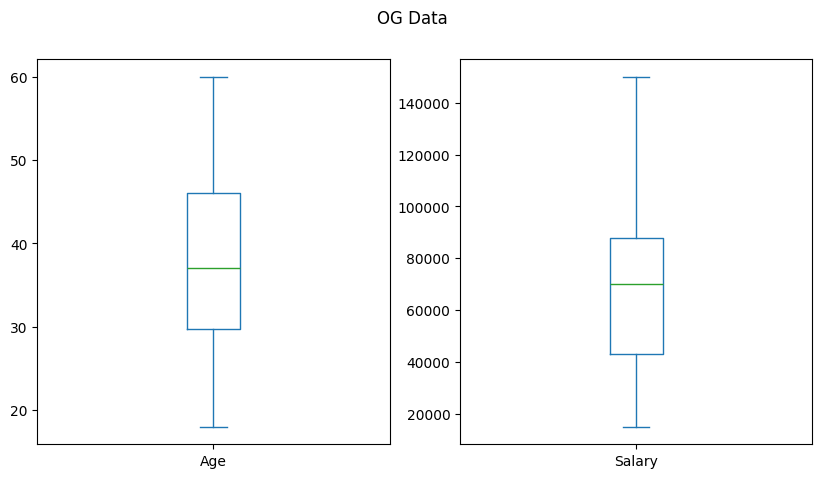

In [73]:
#I generally visualize outliers first so I can decide what type of scaler
#is suitable; more = robustscaler, fewer = standardscaler
df_og[['Age', 'Salary']].plot(kind='box', title='OG Data', figsize=(10,5), subplots=True)
plt.show()

In [74]:
print((df_og[['Age', 'Salary']].skew()).round(2))

Age       0.23
Salary    0.50
dtype: float64


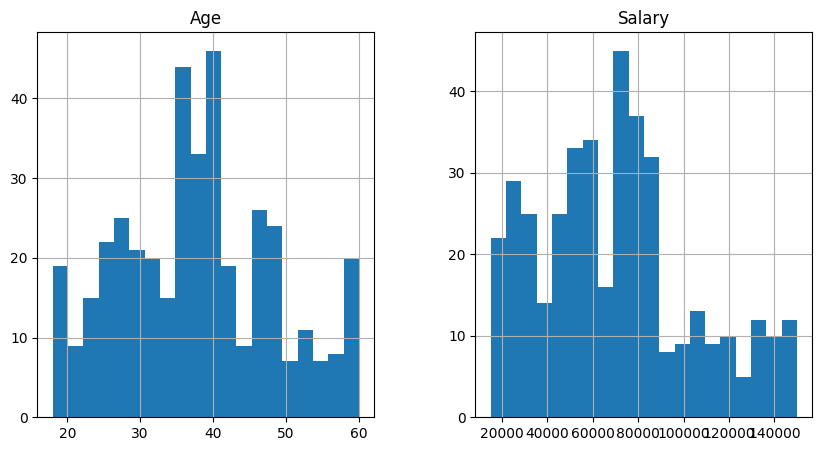

In [75]:
df_og[['Age', 'Salary']].hist(bins=20, figsize=(10,5))
plt.show()

In [76]:
#Data don't have any major issues with outliers, so I'll use standard scaling
scaler = StandardScaler()
standard_cols = ['Age', 'Salary']

X_train[standard_cols] = scaler.fit_transform(X_train[standard_cols])
X_test[standard_cols] = scaler.transform(X_test[standard_cols])

display(X_train.head(3), X_test.head(3))

,Age,Salary
384,1.888902,-1.091379
187,-0.421461,-0.851927
202,0.156130,1.931708


,Age,Salary
8,-1.191581,-1.091379
252,1.022516,1.931708
61,-1.191581,0.524925


### Step 5: Train Logistic Regression Model

In [77]:
log_reg = LogisticRegression(max_iter=995, random_state=25)
log_reg.fit(X_train[['Age', 'Salary']], y_train)

LogisticRegression(max_iter=995, random_state=25)

### Step 6: Predict and Evaluate

In [78]:
preds = log_reg.predict(X_test)
def eval(name, y_true, y_pred):
  print(f'{name} Evaluation',
        f'\n\nAccuracy: {accuracy_score(y_true, y_pred)*100}%',
        f'\n\nClassification Report:\n {classification_report(y_true, y_pred)}',
        f'\nConfusion Matrix:\n {confusion_matrix(y_true, y_pred)}')

eval('Logistic Regression', y_test, preds)

Logistic Regression Evaluation 

Accuracy: 78.75% 

Classification Report:
               precision    recall  f1-score   support

           0       0.69      1.00      0.82        38
           1       1.00      0.60      0.75        42

    accuracy                           0.79        80
   macro avg       0.85      0.80      0.78        80
weighted avg       0.85      0.79      0.78        80
 
Confusion Matrix:
 [[38  0]
 [17 25]]


### Step 7: Visualization of Decision Regions

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


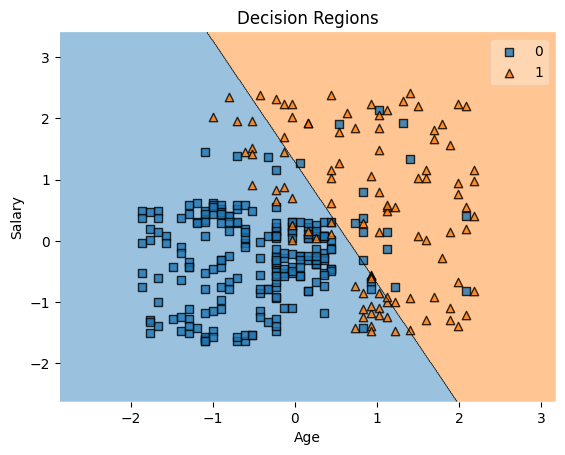

In [79]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(X_train[['Age', 'Salary']].values, y_train.values, clf=log_reg)
plt.xlabel('Age')
plt.ylabel('Salary')
plt.title('Decision Regions')
plt.show()

## IV. Reflection Questions
1. Logistic regression outputs probabilities — why can it still be used for classification?
2. Based on your model, which customers are more likely to purchase a car?
3. What factors might cause low accuracy in this task?
4. Propose additional features or preprocessing steps that could improve accuracy.


#Please write your answer here

1.   Even though logistic regression only outputs probabilities, we can still use it for classification by setting a threshold for delineating class values, i.e., values < x are classified as false, while values >= x are classified as true.
2.   Customers who *did* purchase a car were more likely to both be older and have a higher salary.
3.   Accuracy is highly contingent on training parameters and data wrangling before modeling. A large number of training iterations can decrease testing accuracy through overfitting, poor X/y splits can likewise tank the output of an otherwise healthy model.
4.   Datasets with more dimensions for analysis and training often lend themselves to more precision in a model's predictive ability and, resultingly, accuracy. In my opinion, because this dataset was very small, there's not many additional measures we could take to improve upon the model. Worthwhile features for any similar future analyses would be categorical dimensions (sex, dependents (y/n), geographic location) and total income (specifically determining if the salary of customers' partners also impact purchase, similar to co-applicant data in loan approval)



